# 1.Non Linear Model 

### 1.1 Introduction
In this section, we introduce our non-linear classification model, based on XGBoost. XGBoost was chosen because it can model non-linear decision boundaries, handle high-dimensional feature spaces, and capture interactions between features, which are expected in our dataset. In addition, tree-based models are relatively robust to feature scaling and correlated variables, making XGBoost a strong candidate for this type of neural data.
To ensure a fair and controlled comparison, we start from the same preprocessing pipeline as for the logistic regression (normalization, imputation, feature selection, and LOSO cross-validation). In order to avoid an excessively large and expensive grid search, hyperparameters are not tuned all at once. Instead, we follow a step-by-step strategy, selecting parameters by order of importance through successive iterations, while keeping the rest of the pipeline fixed. This approach reduces computational cost and allows a clearer interpretation of the impact of each group of hyperparameters. It's worth noting that a massive grid search over all possible parameters of the model, by testing every possibility, should be "better" but it's rapidely unfeasible because of the time it would take.


### 1.2 LOSO-Based Optimization of the Three Most Influential XGBoost Hyperparameters
This notebook section performs a grid search for the 3 main XGBoost hyperparameters using a Leave-One-Session-Out (LOSO) cross-validation scheme to avoid leakage across recording sessions. We first load the raw training set, drop constant features, and apply a per-session z-score normalization. Labels are encoded to integers.
For each combination of `n_estimators`, `max_depth`, and `learning_rate` we run LOSO folds where we: 

1) fit a KNN imputer on the training fold only and apply it to the test fold

2) compute ANOVA F-scores on the training fold only to select the top K_FEATURES (here 400) 

3) train an XGBoost classifier and evaluate its accuracy on the held-out session. We report the mean ± std accuracy across sessions and rank all configurations to identify the best-performing hyperparameter triplets.

`n_estimators`, `max_depth`, and `learning_rate` are considered the most important hyperparameters because they directly control the capacity, complexity, and learning dynamics of the XGBoost model:

`n_estimators` controls the number of boosting trees

`max_depth` determines the complexity of individual trees

`learning_rate` regulates how strongly each new tree contributes to the ensemble

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier


# =============================
# 0. Global parameters
# =============================
K_FEATURES = 400
N_NEIGHBORS = 2

PARAM_GRID = {
    "n_estimators": [200, 300, 500, 700],
    "max_depth": [3, 5, 7, 9],
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
}

# =============================
# 1. Load RAW training data
# =============================
df = pd.read_csv("data/raw/train.csv")

# Remove constant columns
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df.columns
    if c not in cols_to_keep and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

# Feature columns
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

# Per-session normalization (z-score)
df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

X = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

# Label encoding
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

# =============================
# 2. LOSO grid search
# =============================
logo = LeaveOneGroupOut()
results = []

for n_estimators in PARAM_GRID["n_estimators"]:
    for max_depth in PARAM_GRID["max_depth"]:
        for learning_rate in PARAM_GRID["learning_rate"]:

            fold_accs = []

            print(
                f"\nTesting: "
                f"n_estimators={n_estimators}, "
                f"max_depth={max_depth}, "
                f"learning_rate={learning_rate}"
            )

            for train_idx, test_idx in logo.split(X, y, groups):

                X_train_raw = X[train_idx]
                X_test_raw  = X[test_idx]
                y_train = y[train_idx]
                y_test  = y[test_idx]

                # --- Imputation
                imputer = KNNImputer(n_neighbors=N_NEIGHBORS)
                X_train_imp = imputer.fit_transform(X_train_raw)
                X_test_imp  = imputer.transform(X_test_raw)

                # --- Select top-K features (TRAIN of the fold only)
                f_scores, _ = f_classif(X_train_imp, y_train)
                f_scores = np.nan_to_num(f_scores, nan=-np.inf)
                topk_idx = np.argsort(f_scores)[-K_FEATURES:]

                X_train_sel = X_train_imp[:, topk_idx]
                X_test_sel  = X_test_imp[:, topk_idx]

                # --- XGBoost model
                model = XGBClassifier(
                    n_estimators=n_estimators,
                    max_depth=max_depth,
                    learning_rate=learning_rate,
                    min_child_weight=1, #default value
                    subsample=0.8, #amount of observations seen by each tree, induce less correlation among trees
                    colsample_bytree=0.8, #amount of features seen by each tree, induce less correlation among trees
                    objective="multi:softprob",#manage multi-class classification better than softmax
                    num_class=num_classes,
                    eval_metric="mlogloss",#logarithmic loss for multi-class, evaluate softprob outputs
                    tree_method="hist", #faster than exact
                    random_state=0,#for reproducibility
                    n_jobs=-1,#use all cores
                )

                model.fit(X_train_sel, y_train)
                y_pred = model.predict(X_test_sel)

                acc = accuracy_score(y_test, y_pred)
                fold_accs.append(acc)

            mean_acc = np.mean(fold_accs)
            std_acc  = np.std(fold_accs)

            results.append({
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "learning_rate": learning_rate,
                "mean_acc": mean_acc,
                "std_acc": std_acc,
            })

            print(f"→ mean accuracy: {mean_acc:.4f} ± {std_acc:.4f}")

# =============================
# 3. Final results
# =============================
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("mean_acc", ascending=False)

print("\n=== TOP 5 CONFIGURATIONS ===")
print(results_df.head())

# save results
results_df.to_csv("xgboost_loso_grid_results.csv", index=False)



Testing: n_estimators=200, max_depth=3, learning_rate=0.03
→ mean accuracy: 0.5481 ± 0.0522

Testing: n_estimators=200, max_depth=3, learning_rate=0.05
→ mean accuracy: 0.5606 ± 0.0443

Testing: n_estimators=200, max_depth=3, learning_rate=0.1
→ mean accuracy: 0.5443 ± 0.0426

Testing: n_estimators=200, max_depth=3, learning_rate=0.2
→ mean accuracy: 0.5523 ± 0.0431

Testing: n_estimators=200, max_depth=5, learning_rate=0.03
→ mean accuracy: 0.5530 ± 0.0569

Testing: n_estimators=200, max_depth=5, learning_rate=0.05
→ mean accuracy: 0.5559 ± 0.0495

Testing: n_estimators=200, max_depth=5, learning_rate=0.1
→ mean accuracy: 0.5561 ± 0.0504

Testing: n_estimators=200, max_depth=5, learning_rate=0.2
→ mean accuracy: 0.5606 ± 0.0539

Testing: n_estimators=200, max_depth=7, learning_rate=0.03
→ mean accuracy: 0.5471 ± 0.0475

Testing: n_estimators=200, max_depth=7, learning_rate=0.05
→ mean accuracy: 0.5571 ± 0.0579

Testing: n_estimators=200, max_depth=7, learning_rate=0.1
→ mean accuracy

### 1.3 Progressive Pipeline Optimization

Interestingly, XGBoost achieves a similar best accuracy to the logistic regression. This suggests that the current pipeline may be overly restrictive and could limit the potential of our non-linear model. To investigate this hypothesis, we refine the pipeline in a step-by-step manner as described in introduction, optimizing one component at a time. At each stage, we select a subset of the best-performing configurations before proceeding to the next step. The successive steps are:
1) Normalisation methode
2) Number of keeped features K
3) imputation strategy
4) regularisation strategy

The tuning order follows a top-down logic: data representation (normalization), model input dimensionality (feature selection), robustness to missing values (imputation), and finally model complexity control (regularization).

### 1.3.1 Normalisation methode

In this section, we use `TOP_TRIPLETS`, i.e. the three best hyperparameter sets identified in the previous iteration, and compare different `NORMALIZATIONS` strategies using these configurations. We additionally test two candidate values of 
`K` from `K_LIST` to ensure that potential interactions between normalization and feature dimensionality are not missed, even though this parameter will be tuned more extensively in the next iteration. 

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier


# =============================
# 0) Step 1 settings (Normalization)
# =============================
K_LIST = [400, 800]
N_NEIGHBORS = 2

# Best triplets from the previous grid search
TOP_TRIPLETS = [
    {"n_estimators": 500, "max_depth": 7, "learning_rate": 0.10},
    {"n_estimators": 300, "max_depth": 9, "learning_rate": 0.05},
    {"n_estimators": 500, "max_depth": 9, "learning_rate": 0.03},
]

#  normalization strategies to compare
NORMALIZATIONS = ["none", "center", "zscore"]


# =============================
# 1) Load RAW training data (no normalization applied here)
# =============================
df = pd.read_csv("data/raw/train.csv")

# Remove constant columns
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df.columns
    if c not in cols_to_keep and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

# Feature columns
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

X_raw = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

# Label encoding
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

logo = LeaveOneGroupOut()


# =============================
# 2) Utility functions
# =============================
def normalize_per_session_matrix(X_mat, g_vec, mode: str):
    """
    Apply a per-session normalization (g_vec) to a matrix X_mat.
    Important: normalization is applied to the full dataset here,
    which is valid because it does not use the labels y.
    """
    if mode == "none":
        return X_mat

    Xn = X_mat.copy()
    # Implemented in numpy to avoid pandas overhead inside the loop
    unique_groups = np.unique(g_vec)

    for sid in unique_groups:
        idx = np.where(g_vec == sid)[0]
        block = Xn[idx, :]

        mu = np.nanmean(block, axis=0)

        if mode == "center":
            Xn[idx, :] = block - mu

        elif mode == "zscore":
            sigma = np.nanstd(block, axis=0)
            sigma = np.where(sigma < 1e-8, 1.0, sigma)
            Xn[idx, :] = (block - mu) / sigma
        else:
            raise ValueError(f"Unknown mode: {mode}")

    return Xn


def eval_config_loso(X, y, groups, k_features, triplet):
    """
    Evaluate a configuration (K + hyperparameter triplet) using LOSO, with:
    - KNN imputation in each fold
    - ANOVA top-K feature selection in each fold
    - XGBoost training and prediction in each fold
    Returns mean_acc, std_acc
    """
    fold_accs = []

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train_raw = X[train_idx]
        X_test_raw  = X[test_idx]
        y_train = y[train_idx]
        y_test  = y[test_idx]

        # Imputation (fit on training fold only)
        imputer = KNNImputer(n_neighbors=N_NEIGHBORS)
        X_train_imp = imputer.fit_transform(X_train_raw)
        X_test_imp  = imputer.transform(X_test_raw)

        # Top-K feature selection on training fold only
        f_scores, _ = f_classif(X_train_imp, y_train)
        f_scores = np.nan_to_num(f_scores, nan=-np.inf)

        k = min(k_features, X_train_imp.shape[1])
        topk_idx = np.argsort(f_scores)[-k:]

        X_train_sel = X_train_imp[:, topk_idx]
        X_test_sel  = X_test_imp[:, topk_idx]

        # Model
        model = XGBClassifier(
            n_estimators=triplet["n_estimators"],
            max_depth=triplet["max_depth"],
            learning_rate=triplet["learning_rate"],
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
        )

        model.fit(X_train_sel, y_train)
        y_pred = model.predict(X_test_sel)
        fold_accs.append(accuracy_score(y_test, y_pred))

    return float(np.mean(fold_accs)), float(np.std(fold_accs))


# =============================
# 3) Step 1: compare normalization strategies
# =============================
results = []

for norm in NORMALIZATIONS:
    print(f"\n==============================")
    print(f"Normalization = {norm}")
    print(f"==============================")

    # Apply normalization to the full feature matrix (no label usage, thus valid)
    X_norm = normalize_per_session_matrix(X_raw, groups, mode=norm)

    for k in K_LIST:
        for t in TOP_TRIPLETS:
            print(
                f"\nTesting norm={norm}, K={k}, "
                f"n_estimators={t['n_estimators']}, max_depth={t['max_depth']}, lr={t['learning_rate']}"
            )

            mean_acc, std_acc = eval_config_loso(X_norm, y, groups, k_features=k, triplet=t)

            results.append({
                "norm": norm,
                "K": k,
                "n_estimators": t["n_estimators"],
                "max_depth": t["max_depth"],
                "learning_rate": t["learning_rate"],
                "mean_acc": mean_acc,
                "std_acc": std_acc,
            })

            print(f"→ mean accuracy: {mean_acc:.4f} ± {std_acc:.4f}")

# Final results
results_df = pd.DataFrame(results).sort_values("mean_acc", ascending=False)

print("\n=== TOP 10 (Step 1: Normalization) ===")
print(results_df.head(10))

# Save results
results_df.to_csv("step1_normalization_results.csv", index=False)
print("\nSaved: step1_normalization_results.csv")



Normalisation = none

Testing norm=none, K=400, n_estimators=500, max_depth=7, lr=0.1
→ mean accuracy: 0.4332 ± 0.0830

Testing norm=none, K=400, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.4242 ± 0.0827

Testing norm=none, K=400, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.4307 ± 0.0853

Testing norm=none, K=800, n_estimators=500, max_depth=7, lr=0.1
→ mean accuracy: 0.4303 ± 0.0912

Testing norm=none, K=800, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.4276 ± 0.0901

Testing norm=none, K=800, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.4270 ± 0.0919

Normalisation = center

Testing norm=center, K=400, n_estimators=500, max_depth=7, lr=0.1


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_78494/1490176925.py:81: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)


→ mean accuracy: 0.5518 ± 0.0744

Testing norm=center, K=400, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.5544 ± 0.0786

Testing norm=center, K=400, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.5562 ± 0.0776

Testing norm=center, K=800, n_estimators=500, max_depth=7, lr=0.1
→ mean accuracy: 0.5440 ± 0.0745

Testing norm=center, K=800, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.5411 ± 0.0731

Testing norm=center, K=800, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.5460 ± 0.0771

Normalisation = zscore

Testing norm=zscore, K=400, n_estimators=500, max_depth=7, lr=0.1


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_78494/1490176925.py:81: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


→ mean accuracy: 0.5624 ± 0.0462

Testing norm=zscore, K=400, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.5537 ± 0.0547

Testing norm=zscore, K=400, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.5633 ± 0.0490

Testing norm=zscore, K=800, n_estimators=500, max_depth=7, lr=0.1
→ mean accuracy: 0.5483 ± 0.0452

Testing norm=zscore, K=800, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.5549 ± 0.0484

Testing norm=zscore, K=800, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.5572 ± 0.0522

=== TOP 10 (Step 1: Normalisation) ===
      norm    K  n_estimators  max_depth  learning_rate  mean_acc   std_acc
14  zscore  400           500          9           0.03  0.563261  0.049021
12  zscore  400           500          7           0.10  0.562447  0.046162
17  zscore  800           500          9           0.03  0.557242  0.052200
8   center  400           500          9           0.03  0.556197  0.077552
16  zscore  800           300          9   

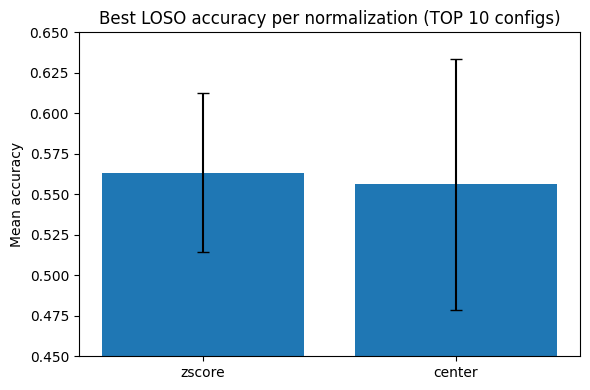

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("step1_normalization_results.csv")

top10 = df.sort_values("mean_acc", ascending=False).head(10)

best_per_norm_top10 = (
    top10.sort_values("mean_acc", ascending=False)
         .groupby("norm", as_index=False)
         .head(1)
)

plt.figure(figsize=(6, 4))
plt.bar(
    best_per_norm_top10["norm"],
    best_per_norm_top10["mean_acc"],
    yerr=best_per_norm_top10["std_acc"],
    capsize=4,
)

plt.ylim(0.45, 0.65)
plt.title("Best LOSO accuracy per normalization (TOP 10 configs)")
plt.ylabel("Mean accuracy")
plt.tight_layout()
plt.show()


We can conclude here that the z-score normalisation works slightly better than the centering especially in the top 3 even if we've some centering in the top 10, we can keep this in mind and keep only the better set of parameter for the centering in following iterations. 

### 1.3.2 Number of keeped features K

According to the F-score scree plot displayed in introduction, almost all the variance is explained by the 500-600 features with the highest F-score. We will then explore numbers in this range to find the best `K`. 


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.impute import KNNImputer
from xgboost import XGBClassifier


# =============================
# 0) Settings 
# =============================
K_LIST = [350, 400, 450, 550]

# Two best z-score configs + the best center config from Step 1
CONFIGS = [
    {"name": "zscore_xgb_9_003", "norm": "zscore", "n_estimators": 500, "max_depth": 9, "learning_rate": 0.03},
    {"name": "zscore_xgb_7_010", "norm": "zscore", "n_estimators": 500, "max_depth": 7, "learning_rate": 0.10},
    {"name": "center_xgb_9_003", "norm": "center", "n_estimators": 500, "max_depth": 9, "learning_rate": 0.03},
]


# =============================
# 1) Load raw data
# =============================
df = pd.read_csv("data/raw/train.csv")

# Drop constant columns
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df.columns
    if c not in cols_to_keep and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

# Feature columns
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

X_raw = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

# Label encoding
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

logo = LeaveOneGroupOut()


# =============================
# 2) Per-session normalization helper
# =============================
def normalize_per_session_matrix(X_mat, g_vec, mode: str):
    if mode == "none":
        return X_mat

    Xn = X_mat.copy()
    for sid in np.unique(g_vec):
        idx = np.where(g_vec == sid)[0]
        block = Xn[idx, :]

        mu = np.nanmean(block, axis=0)

        if mode == "center":
            Xn[idx, :] = block - mu
        elif mode == "zscore":
            sigma = np.nanstd(block, axis=0)
            sigma = np.where(sigma < 1e-8, 1.0, sigma)
            Xn[idx, :] = (block - mu) / sigma
        else:
            raise ValueError(f"Unknown mode: {mode}")

    return Xn


# =============================
# 3) LOSO loop: KNN imputation + ANOVA + XGBoost
# =============================
results = []

for cfg in CONFIGS:
    print(f"\n=== CONFIG: {cfg['name']} (norm={cfg['norm']}) ===")

    # Apply normalization once (no label usage → OK)
    X_norm = normalize_per_session_matrix(X_raw, groups, mode=cfg["norm"])

    for K in K_LIST:
        fold_accs = []

        for train_idx, test_idx in logo.split(X_norm, y, groups):
            X_tr_raw, X_te_raw = X_norm[train_idx], X_norm[test_idx]
            y_tr, y_te = y[train_idx], y[test_idx]

            # KNN imputation (fit on train only)
            imputer = KNNImputer(n_neighbors=2)
            X_tr = imputer.fit_transform(X_tr_raw)
            X_te = imputer.transform(X_te_raw)

            # ANOVA feature ranking on train only
            scores, _ = f_classif(X_tr, y_tr)
            scores = np.nan_to_num(scores, nan=-np.inf)

            k = min(K, X_tr.shape[1])
            idx = np.argsort(scores)[-k:]

            X_tr_sel = X_tr[:, idx]
            X_te_sel = X_te[:, idx]

            # XGBoost (single thread for stability)
            model = XGBClassifier(
                n_estimators=cfg["n_estimators"],
                max_depth=cfg["max_depth"],
                learning_rate=cfg["learning_rate"],
                subsample=0.8,
                colsample_bytree=0.8,
                objective="multi:softprob",
                num_class=num_classes,
                eval_metric="mlogloss",
                tree_method="hist",
                random_state=0,
                n_jobs=-1,
            )

            model.fit(X_tr_sel, y_tr)
            fold_accs.append(accuracy_score(y_te, model.predict(X_te_sel)))

        results.append({
            "config": cfg["name"],
            "norm": cfg["norm"],
            "K": K,
            "n_estimators": cfg["n_estimators"],
            "max_depth": cfg["max_depth"],
            "learning_rate": cfg["learning_rate"],
            "mean_acc": float(np.mean(fold_accs)),
            "std_acc": float(np.std(fold_accs)),
        })

        print(f"K={K:4d} → acc={np.mean(fold_accs):.4f}")


# =============================
# 4) Results
# =============================
res_df = pd.DataFrame(results).sort_values("mean_acc", ascending=False)

print("\n=== TOP RESULTS (K selection, KNN imputation) ===") 
print(res_df.head(20))

res_df.to_csv("step2_K_selection_anova_KNN_zscore_vs_center.csv", index=False)
print("\nSaved: step2_K_selection_anova_KNN_zscore_vs_center.csv")


Although the initial XGBoost hyperparameter search was performed using K = 400, we subsequently evaluated a range of nearby values. The resulting performance curve shows a clear maximum around K = 400, with a consistent decrease for smaller and larger values. This confirms that the chosen dimensionality is not an artifact of the initial choice, but rather reflects a stable optimum of the pipeline. It's worth noting that from the first iteration we fixed K=400 and selected the other parameters thereafter, this way it's possible that we've included a moderate bias related to the pipeline.

### 1.3.3 Imputer

This script evaluates which imputation strategy works best (and compares the best fixed XGBoost configurations found before) under a leakage-safe Leave-One-Session-Out (LOSO) setup.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer, KNNImputer
from xgboost import XGBClassifier


# =============================
# Settings (fixed)
# =============================
K_FEATURES = 400
NORM_MODE = "zscore"

MODELS = [
    {"name": "xgb_9_003",        "n_estimators": 500, "max_depth": 9, "learning_rate": 0.03},
    {"name": "xgb_7_010",        "n_estimators": 500, "max_depth": 7, "learning_rate": 0.10},
    {"name": "xgb_7_010_small",  "n_estimators": 200, "max_depth": 7, "learning_rate": 0.10},
]

IMPUTERS = [
    ("mean", SimpleImputer(strategy="mean")),
    ("knn1", KNNImputer(n_neighbors=1)),
    ("knn2", KNNImputer(n_neighbors=2)),
    ("knn3", KNNImputer(n_neighbors=3)),
]


# =============================
# 1) Load data
# =============================
df = pd.read_csv("data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# drop constant feature columns
constant_cols = [
    c for c in df.columns
    if c not in ID_COLS and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

feature_cols = [c for c in df.columns if c not in ID_COLS]

X_raw = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

logo = LeaveOneGroupOut()


# =============================
# 2) Normalize per session (z-score)
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = np.where(session_ids == sid)[0]
        block = Xn[idx]

        mu = np.nanmean(block, axis=0)
        sigma = np.nanstd(block, axis=0)
        sigma = np.where(sigma < 1e-8, 1.0, sigma)

        Xn[idx] = (block - mu) / sigma
    return Xn

if NORM_MODE == "zscore":
    X_norm = zscore_per_session(X_raw, groups)
elif NORM_MODE == "none":
    X_norm = X_raw
else:
    raise ValueError(f"Unknown NORM_MODE: {NORM_MODE}")


# =============================
# 3) LOSO evaluation
# =============================
summary_rows = []
fold_rows = []

for model_cfg in MODELS:
    print(f"\n==============================")
    print(f"MODEL: {model_cfg['name']}")
    print(f"==============================")

    for imp_name, imp in IMPUTERS:
        print(f"\n--- Imputer: {imp_name} ---")

        fold_accs = []

        for fold_i, (train_idx, test_idx) in enumerate(logo.split(X_norm, y, groups), start=1):
            heldout_sid = groups[test_idx][0]

            X_tr_raw, X_te_raw = X_norm[train_idx], X_norm[test_idx]
            y_tr, y_te = y[train_idx], y[test_idx]

            # 1) Fit imputer on train only
            X_tr = imp.fit_transform(X_tr_raw)
            X_te = imp.transform(X_te_raw)

            # 2) Select top-K features with ANOVA on train only
            scores, _ = f_classif(X_tr, y_tr)
            scores = np.nan_to_num(scores, nan=-np.inf)

            k = min(K_FEATURES, X_tr.shape[1])
            feat_idx = np.argsort(scores)[-k:]

            X_tr_sel = X_tr[:, feat_idx]
            X_te_sel = X_te[:, feat_idx]

            # 3) Train + predict XGBoost
            model = XGBClassifier(
                n_estimators=model_cfg["n_estimators"],
                max_depth=model_cfg["max_depth"],
                learning_rate=model_cfg["learning_rate"],
                min_child_weight=1,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="multi:softprob",
                num_class=num_classes,
                eval_metric="mlogloss",
                tree_method="hist",
                random_state=0,
                n_jobs=-1,
            )

            model.fit(X_tr_sel, y_tr)
            y_pred = model.predict(X_te_sel)
            acc = accuracy_score(y_te, y_pred)

            fold_accs.append(acc)

            fold_rows.append({
                "model": model_cfg["name"],
                "imputer": imp_name,
                "fold": fold_i,
                "heldout_session_id": heldout_sid,
                "K": K_FEATURES,
                "norm": NORM_MODE,
                "acc": float(acc),
            })

            print(f"  Fold {fold_i:02d} | held-out session {heldout_sid} | acc = {acc:.4f}")

        mean_acc = float(np.mean(fold_accs))
        std_acc = float(np.std(fold_accs))

        summary_rows.append({
            "model": model_cfg["name"],
            "imputer": imp_name,
            "K": K_FEATURES,
            "norm": NORM_MODE,
            "mean_acc": mean_acc,
            "std_acc": std_acc,
        })

        print(f"→ mean accuracy: {mean_acc:.4f} ± {std_acc:.4f}")


# =============================
# 4) Save results
# =============================
summary_df = pd.DataFrame(summary_rows).sort_values("mean_acc", ascending=False)
folds_df = pd.DataFrame(fold_rows).sort_values(["model", "imputer", "fold"])

print("\n=== TOP RESULTS (summary) ===")
print(summary_df)

summary_df.to_csv("step3_imputer_selection_summary.csv", index=False)
folds_df.to_csv("step3_imputer_selection_folds.csv", index=False)

print("\nSaved: step3_imputer_selection_summary.csv")
print("Saved: step3_imputer_selection_folds.csv")


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3865038602.py:67: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



MODEL: xgb_9_003

--- Imputer: mean ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5710
  Fold 02 | held-out session PG082_20221114 | acc = 0.6515
  Fold 03 | held-out session PG083_20221125 | acc = 0.5833
  Fold 04 | held-out session PG083_20221129 | acc = 0.5342
  Fold 05 | held-out session PG084_20221206 | acc = 0.5591
  Fold 06 | held-out session PG084_20221207 | acc = 0.5771
  Fold 07 | held-out session PG085_20221213 | acc = 0.4653


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


  Fold 08 | held-out session PG085_20221214 | acc = 0.5486
→ mean accuracy: 0.5613 ± 0.0488

--- Imputer: knn1 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5755
  Fold 02 | held-out session PG082_20221114 | acc = 0.6156
  Fold 03 | held-out session PG083_20221125 | acc = 0.5802
  Fold 04 | held-out session PG083_20221129 | acc = 0.5408
  Fold 05 | held-out session PG084_20221206 | acc = 0.5669
  Fold 06 | held-out session PG084_20221207 | acc = 0.5745
  Fold 07 | held-out session PG085_20221213 | acc = 0.4634
  Fold 08 | held-out session PG085_20221214 | acc = 0.5576
→ mean accuracy: 0.5593 ± 0.0414

--- Imputer: knn2 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5846
  Fold 02 | held-out session PG082_20221114 | acc = 0.6482
  Fold 03 | held-out session PG083_20221125 | acc = 0.5802
  Fold 04 | held-out session PG083_20221129 | acc = 0.5386
  Fold 05 | held-out session PG084_20221206 | acc = 0.5551
  Fold 06 | held-out session PG084_20221207 | acc = 0.5785
  F

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


  Fold 08 | held-out session PG085_20221214 | acc = 0.5324
→ mean accuracy: 0.5528 ± 0.0465

--- Imputer: knn1 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5695
  Fold 02 | held-out session PG082_20221114 | acc = 0.6319
  Fold 03 | held-out session PG083_20221125 | acc = 0.5896
  Fold 04 | held-out session PG083_20221129 | acc = 0.5673
  Fold 05 | held-out session PG084_20221206 | acc = 0.5512
  Fold 06 | held-out session PG084_20221207 | acc = 0.5864
  Fold 07 | held-out session PG085_20221213 | acc = 0.4465
  Fold 08 | held-out session PG085_20221214 | acc = 0.5683
→ mean accuracy: 0.5639 ± 0.0497

--- Imputer: knn2 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5755
  Fold 02 | held-out session PG082_20221114 | acc = 0.6384
  Fold 03 | held-out session PG083_20221125 | acc = 0.5818
  Fold 04 | held-out session PG083_20221129 | acc = 0.5342
  Fold 05 | held-out session PG084_20221206 | acc = 0.5669
  Fold 06 | held-out session PG084_20221207 | acc = 0.5691
  F

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


  Fold 08 | held-out session PG085_20221214 | acc = 0.5288
→ mean accuracy: 0.5491 ± 0.0535

--- Imputer: knn1 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5785
  Fold 02 | held-out session PG082_20221114 | acc = 0.6450
  Fold 03 | held-out session PG083_20221125 | acc = 0.5865
  Fold 04 | held-out session PG083_20221129 | acc = 0.5475
  Fold 05 | held-out session PG084_20221206 | acc = 0.5531
  Fold 06 | held-out session PG084_20221207 | acc = 0.5745
  Fold 07 | held-out session PG085_20221213 | acc = 0.4484
  Fold 08 | held-out session PG085_20221214 | acc = 0.5701
→ mean accuracy: 0.5630 ± 0.0514

--- Imputer: knn2 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5785
  Fold 02 | held-out session PG082_20221114 | acc = 0.6352
  Fold 03 | held-out session PG083_20221125 | acc = 0.5692
  Fold 04 | held-out session PG083_20221129 | acc = 0.5276
  Fold 05 | held-out session PG084_20221206 | acc = 0.5650
  Fold 06 | held-out session PG084_20221207 | acc = 0.5758
  F

Globally, KNN 1 and 2 are better than KNN 3, increasing the number of neighbors beyond 2 does not bring additional benefit in this setting. We can keep in mind that mean was good too since the differences in the head values of `TOP RESULTS`are very small, mean imputation performs comparably on average, but is less robust due to degenerate features in some LOSO folds. We can associate KNN 1 to xgb_7_010 and its small variant and KNN2 to xgb_9_003 but no strong interaction between the imputation method and the XGBoost configuration is observed. KNN with 1 or 2 neighbors consistently yields competitive performance across all tested models.

Since the iterative imputer is computationally expensive, we did not include it in the full LOSO imputation comparison. Instead, we performed a targeted evaluation on a single held-out session using the best performing XGBoost configuration and the previously selected imputation strategy. This controlled single-fold test allows us to assess whether the iterative imputer provides a meaningful performance gain before considering a more costly full cross-validation.

To do so we selected 2 folds: the one that always provides bad results `PG085_20221213` and an other arbitrary representative fold `PG083_20221125`.

In [10]:
import pandas as pd
import numpy as np
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier


# =============================
# Fixed best pipeline
# =============================
K_FEATURES = 400

FOLDS_TO_TEST = [
    "PG085_20221213",  # worst fold 
    "PG083_20221125",  # representative fold
]

MODEL_CFG = {
    "n_estimators": 500,
    "max_depth": 7,
    "learning_rate": 0.10,
}


# =============================
# Load & preprocess data
# =============================
df = pd.read_csv("data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# drop global constant columns
constant_cols = [
    c for c in df.columns
    if c not in ID_COLS and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

feature_cols = [c for c in df.columns if c not in ID_COLS]

X_raw = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)


# =============================
# Exact same normalization as base pipeline
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = np.where(session_ids == sid)[0]
        block = Xn[idx]

        mu = np.nanmean(block, axis=0)
        sigma = np.nanstd(block, axis=0)
        sigma = np.where(sigma < 1e-8, 1.0, sigma)

        Xn[idx] = (block - mu) / sigma
    return Xn


X = zscore_per_session(X_raw, groups)


# =============================
# Helper: evaluate one fold + one imputer
# =============================
def eval_fold(session_id, imputer, name):
    logo = LeaveOneGroupOut()

    for train_idx, test_idx in logo.split(X, y, groups):
        if groups[test_idx][0] == session_id:
            break

    X_train_raw = X[train_idx]
    X_test_raw  = X[test_idx]
    y_train = y[train_idx]
    y_test  = y[test_idx]

    # Imputation (fit on train only)
    X_train_imp = imputer.fit_transform(X_train_raw)
    X_test_imp  = imputer.transform(X_test_raw)

    # ANOVA top-K (train only)
    scores, _ = f_classif(X_train_imp, y_train)
    scores = np.nan_to_num(scores, nan=-np.inf)
    topk_idx = np.argsort(scores)[-K_FEATURES:]

    X_tr = X_train_imp[:, topk_idx]
    X_te = X_test_imp[:, topk_idx]

    model = XGBClassifier(
        n_estimators=MODEL_CFG["n_estimators"],
        max_depth=MODEL_CFG["max_depth"],
        learning_rate=MODEL_CFG["learning_rate"],
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=0,
        n_jobs=-1,
    )

    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    acc = accuracy_score(y_test, y_pred)

    print(f"{name:<28s} | acc = {acc:.4f}")
    return acc


# =============================
# Run comparison
# =============================
print("\n=== Iterative vs KNN (2-fold test) ===")

for sid in FOLDS_TO_TEST:
    print(f"\n--- Held-out session: {sid} ---")

    acc_knn = eval_fold(
        sid,
        KNNImputer(n_neighbors=1),
        "KNNImputer (k=1)"
    )

    acc_iter = eval_fold(
        sid,
        IterativeImputer(
            estimator=BayesianRidge(),
            max_iter=10,
            n_nearest_features=50,
            tol=1e-2,
            sample_posterior=False,
            random_state=0,
            skip_complete=True,
        ),
        "IterativeImputer (max_iter=3)"
    )

    print(f"Δ (iterative - knn1): {acc_iter - acc_knn:+.4f}")


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3226091643.py:66: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



=== Iterative vs KNN (2-fold test) ===

--- Held-out session: PG085_20221213 ---
KNNImputer (k=1)             | acc = 0.4465


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


IterativeImputer (max_iter=3) | acc = 0.4540
Δ (iterative - knn1): +0.0075

--- Held-out session: PG083_20221125 ---
KNNImputer (k=1)             | acc = 0.5896


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


IterativeImputer (max_iter=3) | acc = 0.5928
Δ (iterative - knn1): +0.0031


Although a lightweight iterative imputation strategy yielded a small performance improvement on a limited number of folds, the effect was not robust and did not persist with increased iterations. Given the substantially higher computational cost and the lack of consistent gains across folds, iterative imputation was not retained in the final pipeline. KNN imputation was selected for its stability, simplicity, and comparable performance.

### 1.3.4 Regularization Strategy
In the final tuning stage, we focused on regularization parameters of the XGBoost model while keeping the entire preprocessing pipeline fixed. Specifically, per-session z-score normalization, KNN imputation (k=1,2), and ANOVA-based top-400 feature selection were applied within each LOSO fold. Regularization was explored across three representative XGBoost configurations using a reduced grid. This approach allows us to assess whether explicit regularization improves predictive accuracy and stability across sessions without confounding effects from earlier pipeline choices. More explicitely we vary these parameters:

`min_child_weight` controls the minimum amount of data required to create a split. Increasing this value prevents the model from creating splits based on very small or session-specific subsets of samples.

`gamma` imposes a minimum gain required to perform a split, effectively discouraging weak or noisy splits that do not significantly improve the objective.

`reg_lambda` (L2 regularization) penalizes large leaf weights, stabilizing predictions and reducing variance.

`reg_alpha` (L1 regularization) enforces sparsity in leaf weights; it is set to zero here because sparsity is already induced upstream by ANOVA feature selection and feature subsampling.


We do not perform an extensive search on this section, the idea was to determine if a moderate or a strong regularization helped the tested models. 


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier


# =============================
# Fixed pipeline settings
# =============================
K_FEATURES = 400
NORM = "zscore"

MODELS = [
    dict(name="xgb_7_010",       n_estimators=500, max_depth=7, learning_rate=0.10, knn_k=1),
    dict(name="xgb_9_003",       n_estimators=500, max_depth=9, learning_rate=0.03, knn_k=2),
    dict(name="xgb_7_010_small", n_estimators=200, max_depth=7, learning_rate=0.10, knn_k=1),
]

REG_SETS = {
    "baseline": dict(min_child_weight=1,  gamma=0.0, reg_lambda=1.0,  reg_alpha=0.0),
    "moderate": dict(min_child_weight=5,  gamma=0.1, reg_lambda=5.0,  reg_alpha=0.0),
    "strong":   dict(min_child_weight=10, gamma=0.3, reg_lambda=10.0, reg_alpha=0.0),
}


# =============================
# Load data
# =============================
df = pd.read_csv("data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]
const_cols = [c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1]
df = df.drop(columns=const_cols)

feature_cols = [c for c in df.columns if c not in ID_COLS]

X = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

logo = LeaveOneGroupOut()


# =============================
# Per-session z-score 
# =============================
Xz = X.copy()
for sid in np.unique(groups):
    idx = groups == sid
    mu = np.nanmean(Xz[idx], axis=0)
    sigma = np.nanstd(Xz[idx], axis=0)
    sigma[sigma < 1e-8] = 1.0
    Xz[idx] = (Xz[idx] - mu) / sigma


# =============================
# Evaluation
# =============================
results = []

for model_cfg in MODELS:
    print(f"\n==============================")
    print(f"MODEL: {model_cfg['name']}")
    print(f"==============================")

    for reg_name, reg in REG_SETS.items():
        fold_accs = []

        for train_idx, test_idx in logo.split(Xz, y, groups):
            X_tr, X_te = Xz[train_idx], Xz[test_idx]
            y_tr, y_te = y[train_idx], y[test_idx]

            # Imputation
            imputer = KNNImputer(n_neighbors=model_cfg["knn_k"])
            X_tr = imputer.fit_transform(X_tr)
            X_te = imputer.transform(X_te)

            # ANOVA selection (train only)
            scores, _ = f_classif(X_tr, y_tr)
            scores = np.nan_to_num(scores, nan=-np.inf)
            topk = np.argsort(scores)[-K_FEATURES:]

            X_tr = X_tr[:, topk]
            X_te = X_te[:, topk]

            model = XGBClassifier(
                n_estimators=model_cfg["n_estimators"],
                max_depth=model_cfg["max_depth"],
                learning_rate=model_cfg["learning_rate"],
                subsample=0.8,
                colsample_bytree=0.8,
                objective="multi:softprob",
                num_class=num_classes,
                eval_metric="mlogloss",
                tree_method="hist",
                random_state=0,
                n_jobs=-1,
                **reg,
            )

            model.fit(X_tr, y_tr)
            y_pred = model.predict(X_te)
            fold_accs.append(accuracy_score(y_te, y_pred))

        mean_acc = np.mean(fold_accs)
        std_acc = np.std(fold_accs)

        print(f"{reg_name:>9} | acc = {mean_acc:.4f} ± {std_acc:.4f}")

        results.append({
            "model": model_cfg["name"],
            "reg": reg_name,
            "mean_acc": mean_acc,
            "std_acc": std_acc,
        })


results_df = pd.DataFrame(results).sort_values("mean_acc", ascending=False)
results_df.to_csv("regularization_simple_test.csv", index=False)

print("\n=== SUMMARY ===")
print(results_df)


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/1452548196.py:60: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xz[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



MODEL: xgb_7_010
 baseline | acc = 0.5639 ± 0.0497
 moderate | acc = 0.5560 ± 0.0443
   strong | acc = 0.5523 ± 0.0535

MODEL: xgb_9_003
 baseline | acc = 0.5633 ± 0.0490
 moderate | acc = 0.5581 ± 0.0460
   strong | acc = 0.5595 ± 0.0482

MODEL: xgb_7_010_small
 baseline | acc = 0.5630 ± 0.0514
 moderate | acc = 0.5559 ± 0.0474
   strong | acc = 0.5552 ± 0.0567

=== SUMMARY ===
             model       reg  mean_acc   std_acc
0        xgb_7_010  baseline  0.563856  0.049745
3        xgb_9_003  baseline  0.563261  0.049021
6  xgb_7_010_small  baseline  0.562951  0.051432
5        xgb_9_003    strong  0.559525  0.048215
4        xgb_9_003  moderate  0.558121  0.046035
1        xgb_7_010  moderate  0.555994  0.044282
7  xgb_7_010_small  moderate  0.555857  0.047366
8  xgb_7_010_small    strong  0.555212  0.056671
2        xgb_7_010    strong  0.552305  0.053473


The regularization grid search shows that adding explicit regularization consistently decreases performance across all tested XGBoost configurations. The baseline models achieve the highest mean accuracy and comparable variability, indicating that the existing pipeline already provides sufficient regularization.
To ensure the model do not apply a too strong regularization we can perform a mini test with the baseline parameters vs weak regularization parameters on one model. 

In [16]:
import pandas as pd
import numpy as np

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier


# =============================
# Fixed pipeline settings (unchanged)
# =============================
K_FEATURES = 400

MODEL = dict(
    name="xgb_7_010",
    n_estimators=500,
    max_depth=7,
    learning_rate=0.10,
    knn_k=1,
)

# Only 2 reg settings: baseline vs slightly weaker L2
REG_SETS = {
    "baseline": dict(min_child_weight=1, gamma=0.0, reg_lambda=1.0, reg_alpha=0.0),
    "weak":     dict(min_child_weight=1, gamma=0.0, reg_lambda=0.5, reg_alpha=0.0),
}


# =============================
# Load data 
# =============================
df = pd.read_csv("data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]
const_cols = [c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1]
df = df.drop(columns=const_cols)

feature_cols = [c for c in df.columns if c not in ID_COLS]

X = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

logo = LeaveOneGroupOut()


# =============================
# Per-session z-score
# =============================
Xz = X.copy()
for sid in np.unique(groups):
    idx = groups == sid
    mu = np.nanmean(Xz[idx], axis=0)
    sigma = np.nanstd(Xz[idx], axis=0)
    sigma[sigma < 1e-8] = 1.0
    Xz[idx] = (Xz[idx] - mu) / sigma


# =============================
# Evaluation 
# =============================
print(f"\nMODEL: {MODEL['name']} (knn_k={MODEL['knn_k']}, K={K_FEATURES}, zscore per session)")

for reg_name, reg in REG_SETS.items():
    fold_accs = []

    for train_idx, test_idx in logo.split(Xz, y, groups):
        X_tr, X_te = Xz[train_idx], Xz[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]

        # Imputation 
        imputer = KNNImputer(n_neighbors=MODEL["knn_k"])
        X_tr = imputer.fit_transform(X_tr)
        X_te = imputer.transform(X_te)

        # ANOVA selection 
        scores, _ = f_classif(X_tr, y_tr)
        scores = np.nan_to_num(scores, nan=-np.inf)
        topk = np.argsort(scores)[-K_FEATURES:]

        X_tr = X_tr[:, topk]
        X_te = X_te[:, topk]

        # XGBoost 
        model = XGBClassifier(
            n_estimators=MODEL["n_estimators"],
            max_depth=MODEL["max_depth"],
            learning_rate=MODEL["learning_rate"],
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
            **reg,
        )

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        fold_accs.append(accuracy_score(y_te, y_pred))

    mean_acc = float(np.mean(fold_accs))
    std_acc = float(np.std(fold_accs))
    print(f"{reg_name:>8} | acc = {mean_acc:.4f} ± {std_acc:.4f}")


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3345168305.py:61: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xz[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



MODEL: xgb_7_010 (knn_k=1, K=400, zscore per session)
baseline | acc = 0.5639 ± 0.0497
    weak | acc = 0.5596 ± 0.0463


We can observe that the weak regulariastion (lower L2 regularisation) do not lead to a better accuracy. 

Finally, we keep these 2 models as our best performing models after all search iterations:

`xgb_7_010`: n_estimators=500, max_depth=7, learning_rate=0.10, knn_k=1 

`xgb_9_003`: n_estimators=500, max_depth=9, learning_rate=0.03, knn_k=2

The rest of the pipeline is not changed as the best normalisaton is zscore and `K`=400 is better. 

### 2. Final LOSO 
In this section we perform the final LOSO for the 2 best models we've foud with the best pipeline parameters. 

/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3513909783.py:67: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



MODEL: xgb_7_010 | IMPUTER: knn1
  Fold 01 | held-out session PG082_20221113 | acc = 0.5695
  Fold 02 | held-out session PG082_20221114 | acc = 0.6319
  Fold 03 | held-out session PG083_20221125 | acc = 0.5896
  Fold 04 | held-out session PG083_20221129 | acc = 0.5673
  Fold 05 | held-out session PG084_20221206 | acc = 0.5512
  Fold 06 | held-out session PG084_20221207 | acc = 0.5864
  Fold 07 | held-out session PG085_20221213 | acc = 0.4465
  Fold 08 | held-out session PG085_20221214 | acc = 0.5683
→ FINAL LOSO: 0.5639 ± 0.0497


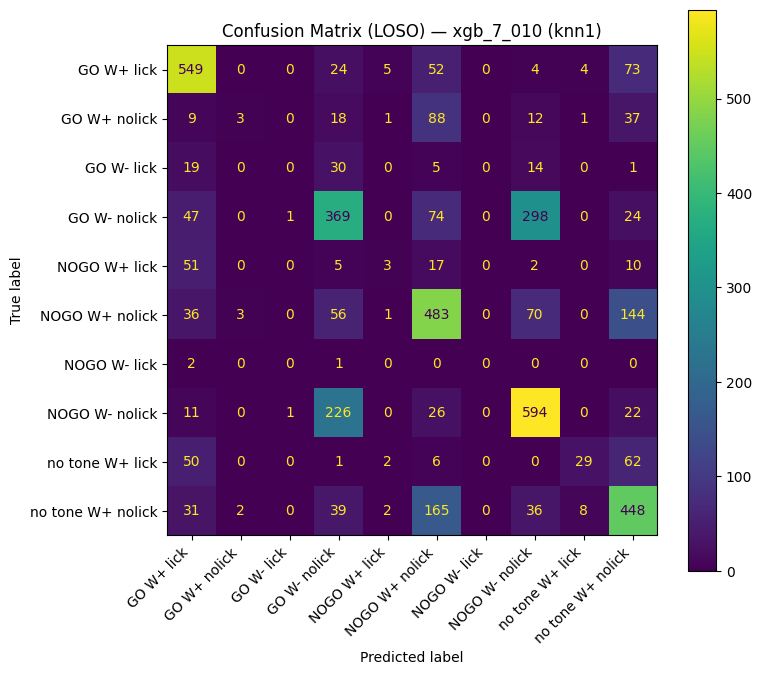


MODEL: xgb_9_003 | IMPUTER: knn2
  Fold 01 | held-out session PG082_20221113 | acc = 0.5846
  Fold 02 | held-out session PG082_20221114 | acc = 0.6482
  Fold 03 | held-out session PG083_20221125 | acc = 0.5802
  Fold 04 | held-out session PG083_20221129 | acc = 0.5386
  Fold 05 | held-out session PG084_20221206 | acc = 0.5551
  Fold 06 | held-out session PG084_20221207 | acc = 0.5785
  Fold 07 | held-out session PG085_20221213 | acc = 0.4615
  Fold 08 | held-out session PG085_20221214 | acc = 0.5594
→ FINAL LOSO: 0.5633 ± 0.0490


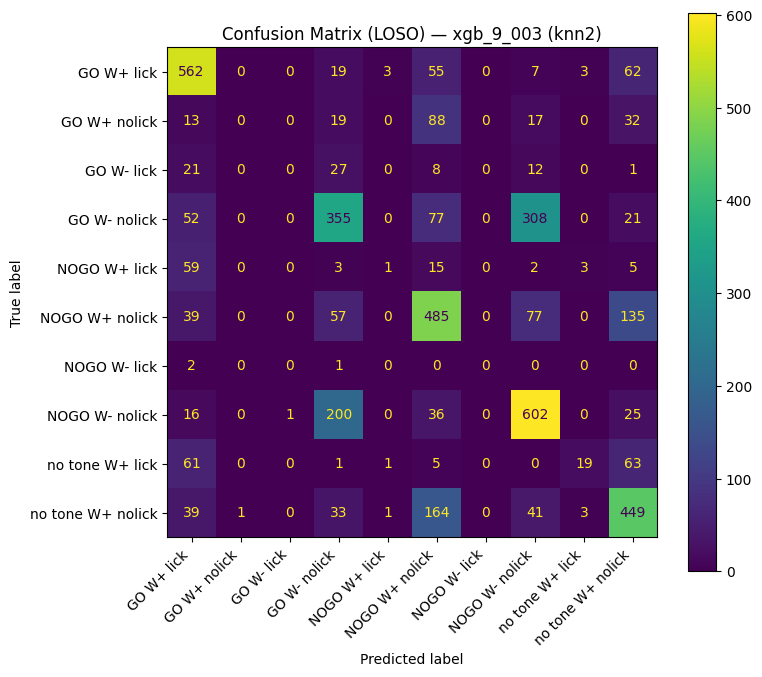


=== FINAL RESULTS (summary) ===
       model imputer    K    norm  mean_acc   std_acc
0  xgb_7_010    knn1  400  zscore  0.563856  0.049745
1  xgb_9_003    knn2  400  zscore  0.563261  0.049021

Saved: final_loso_2models_summary.csv
Saved: final_loso_2models_folds.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.impute import KNNImputer

from xgboost import XGBClassifier


# =============================
# Settings (final LOSO)
# =============================
K_FEATURES = 400
NORM_MODE = "zscore"

MODELS = [
    dict(
        name="xgb_7_010",
        n_estimators=500, max_depth=7, learning_rate=0.10,
        imputer=KNNImputer(n_neighbors=1), imputer_name="knn1",
    ),
    dict(
        name="xgb_9_003",
        n_estimators=500, max_depth=9, learning_rate=0.03,
        imputer=KNNImputer(n_neighbors=2), imputer_name="knn2",
    ),
]


# =============================
# 1) Load data
# =============================
df = pd.read_csv("data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

constant_cols = [c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1]
df = df.drop(columns=constant_cols)

feature_cols = [c for c in df.columns if c not in ID_COLS]

X_raw = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

le = LabelEncoder()
y = le.fit_transform(y_str)
class_names = list(le.classes_)
num_classes = len(class_names)

logo = LeaveOneGroupOut()


# =============================
# 2) Normalize per session (z-score)  
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = np.where(session_ids == sid)[0]
        block = Xn[idx]

        mu = np.nanmean(block, axis=0)
        sigma = np.nanstd(block, axis=0)
        sigma = np.where(sigma < 1e-8, 1.0, sigma)

        Xn[idx] = (block - mu) / sigma
    return Xn

if NORM_MODE == "zscore":
    X_norm = zscore_per_session(X_raw, groups)
elif NORM_MODE == "none":
    X_norm = X_raw
else:
    raise ValueError(f"Unknown NORM_MODE: {NORM_MODE}")


# =============================
# 3) Final LOSO (2 models) + Confusion matrices
# =============================
summary_rows = []
fold_rows = []

for cfg in MODELS:
    print("\n==============================")
    print(f"MODEL: {cfg['name']} | IMPUTER: {cfg['imputer_name']}")
    print("==============================")

    fold_accs = []
    y_true_all, y_pred_all = [], []

    for fold_i, (train_idx, test_idx) in enumerate(logo.split(X_norm, y, groups), start=1):
        heldout_sid = groups[test_idx][0]

        X_tr_raw, X_te_raw = X_norm[train_idx], X_norm[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]

        # 1) Imputation
        imp = cfg["imputer"]
        X_tr = imp.fit_transform(X_tr_raw)
        X_te = imp.transform(X_te_raw)

        # 2) Top-K ANOVA 
        scores, _ = f_classif(X_tr, y_tr)
        scores = np.nan_to_num(scores, nan=-np.inf)

        k = min(K_FEATURES, X_tr.shape[1])
        feat_idx = np.argsort(scores)[-k:]

        X_tr_sel = X_tr[:, feat_idx]
        X_te_sel = X_te[:, feat_idx]

        # 3) XGBoost 
        model = XGBClassifier(
            n_estimators=cfg["n_estimators"],
            max_depth=cfg["max_depth"],
            learning_rate=cfg["learning_rate"],
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
        )

        model.fit(X_tr_sel, y_tr)
        y_pred = model.predict(X_te_sel)
        acc = accuracy_score(y_te, y_pred)

        fold_accs.append(acc)
        y_true_all.append(y_te)
        y_pred_all.append(y_pred)

        fold_rows.append({
            "model": cfg["name"],
            "imputer": cfg["imputer_name"],
            "fold": fold_i,
            "heldout_session_id": heldout_sid,
            "K": K_FEATURES,
            "norm": NORM_MODE,
            "acc": float(acc),
        })

        print(f"  Fold {fold_i:02d} | held-out session {heldout_sid} | acc = {acc:.4f}")

    # ---- Summary + global confusion matrix ----
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)

    mean_acc = float(np.mean(fold_accs))
    std_acc = float(np.std(fold_accs))

    summary_rows.append({
        "model": cfg["name"],
        "imputer": cfg["imputer_name"],
        "K": K_FEATURES,
        "norm": NORM_MODE,
        "mean_acc": mean_acc,
        "std_acc": std_acc,
    })

    print(f"→ FINAL LOSO: {mean_acc:.4f} ± {std_acc:.4f}")

    cm = confusion_matrix(y_true_all, y_pred_all, labels=np.arange(num_classes))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    fig, ax = plt.subplots(figsize=(8, 7))
    disp.plot(ax=ax, values_format="d")
    ax.set_title(f"Confusion Matrix (LOSO) — {cfg['name']} ({cfg['imputer_name']})")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


# =============================
# 4) Save results
# =============================
summary_df = pd.DataFrame(summary_rows).sort_values("mean_acc", ascending=False)
folds_df = pd.DataFrame(fold_rows).sort_values(["model", "fold"])

print("\n=== FINAL RESULTS (summary) ===")
print(summary_df)

summary_df.to_csv("final_loso_2models_summary.csv", index=False)
folds_df.to_csv("final_loso_2models_folds.csv", index=False)

print("\nSaved: final_loso_2models_summary.csv")
print("Saved: final_loso_2models_folds.csv")


The confusion matrices indicate that a substantial fraction of misclassifications involves transitions between GO and NOGO conditions, particularly when the tone is the primary changing cue. However, this pattern must be interpreted with caution. For certain classes such as W− nolick, the absolute number of errors is large mainly because these conditions are highly represented in the dataset. In relative terms, the proportion of correctly classified samples for these classes remains high. Thus, while GO–NOGO confusions constitute an important source of error, they do not necessarily reflect poor separability for all involved conditions, but rather a combination of subtle cue differences and class frequency imbalance.

### 3. Submission 
In this section we prepare the submission folders for the 2 best models tuned in the previous section.

In [18]:
import pandas as pd
import numpy as np

from sklearn.impute import KNNImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif

from xgboost import XGBClassifier


# =============================
# Settings (final)
# =============================
K_FEATURES = 400

REG_BASELINE = dict(min_child_weight=1, gamma=0.0, reg_lambda=1.0, reg_alpha=0.0)

MODELS = [
    dict(
        name="xgb_7_010__500trees_depth7_lr0p10__knn1__K400__zscore_session__REGbaseline",
        n_estimators=500, max_depth=7, learning_rate=0.10,
        imputer=KNNImputer(n_neighbors=1),
        imputer_tag="knn1",
    ),
    dict(
        name="xgb_9_003__500trees_depth9_lr0p03__knn2__K400__zscore_session__REGbaseline",
        n_estimators=500, max_depth=9, learning_rate=0.03,
        imputer=KNNImputer(n_neighbors=2),
        imputer_tag="knn2",
    ),
]


# =============================
# Utils: z-score par session (EXACTEMENT comme ton grid)
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = np.where(session_ids == sid)[0]
        block = Xn[idx]

        mu = np.nanmean(block, axis=0)
        sigma = np.nanstd(block, axis=0)
        sigma = np.where(sigma < 1e-8, 1.0, sigma)

        Xn[idx] = (block - mu) / sigma
    return Xn


# =============================
# 1) Load TRAIN (complet) + preproc commun
# =============================
train = pd.read_csv("data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# drop constant columns (comme ton script)
constant_cols = [c for c in train.columns if c not in ID_COLS and train[c].nunique() <= 1]
train = train.drop(columns=constant_cols)

feature_cols = [c for c in train.columns if c not in ID_COLS]

X_train_raw = train[feature_cols].to_numpy()
y_train_str = train["TRIAL_TYPE"].to_numpy()
groups_train = train["session_id"].to_numpy()

# labels
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)
num_classes = len(le.classes_)
print("Classes:", le.classes_)

# z-score par session (sur tout le train)
X_train_norm = zscore_per_session(X_train_raw, groups_train)


# =============================
# 2) Load TEST + preproc commun (z-score par session)
# =============================
test = pd.read_csv("data/raw/test.csv")

needed_cols = ["session_id", "trial_number"] + feature_cols
test = test[needed_cols].copy()

X_test_raw = test[feature_cols].to_numpy()
groups_test = test["session_id"].to_numpy()

# z-score par session (sur tout le test)
X_test_norm = zscore_per_session(X_test_raw, groups_test)


# =============================
# 3) Train + Predict + Save submission for each model
# =============================
sample = pd.read_csv("data/raw/sample_submission.csv")

for cfg in MODELS:
    print("\n==============================")
    print(f"Training model: {cfg['name']}")
    print("==============================")

    # 1) Imputation (fit sur tout le train)
    imputer = cfg["imputer"]
    X_tr_imp = imputer.fit_transform(X_train_norm)
    X_te_imp = imputer.transform(X_test_norm)

    # 2) Feature selection top-K (fit sur tout le train)
    scores, _ = f_classif(X_tr_imp, y_train)
    scores = np.nan_to_num(scores, nan=-np.inf)

    k = min(K_FEATURES, X_tr_imp.shape[1])
    feat_idx = np.argsort(scores)[-k:]

    X_tr_final = X_tr_imp[:, feat_idx]
    X_te_final = X_te_imp[:, feat_idx]

    # 3) XGBoost (baseline reg)
    model = XGBClassifier(
        n_estimators=cfg["n_estimators"],
        max_depth=cfg["max_depth"],
        learning_rate=cfg["learning_rate"],

        subsample=0.8,
        colsample_bytree=0.8,

        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        tree_method="hist",

        random_state=0,
        n_jobs=-1,

        **REG_BASELINE,
    )

    model.fit(X_tr_final, y_train)

    # 4) Predict
    y_pred_int = model.predict(X_te_final)
    y_pred_str = le.inverse_transform(y_pred_int)

    # 5) Submission
    submission = sample.copy()
    submission["TRIAL_TYPE"] = y_pred_str

    out_path = f"submission__{cfg['name']}.csv"
    submission.to_csv(out_path, index=False)

    print(f"Saved: {out_path}")
    print(submission.head())


Classes: ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/4176694203.py:43: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/4176694203.py:43: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



Training model: xgb_7_010__500trees_depth7_lr0p10__knn1__K400__zscore_session__REGbaseline
Saved: submission__xgb_7_010__500trees_depth7_lr0p10__knn1__K400__zscore_session__REGbaseline.csv
   ID    TRIAL_TYPE
0   1  GO W- nolick
1   2    GO W+ lick
2   3  GO W- nolick
3   4    GO W+ lick
4   5    GO W+ lick

Training model: xgb_9_003__500trees_depth9_lr0p03__knn2__K400__zscore_session__REGbaseline
Saved: submission__xgb_9_003__500trees_depth9_lr0p03__knn2__K400__zscore_session__REGbaseline.csv
   ID         TRIAL_TYPE
0   1     NOGO W- nolick
1   2         GO W+ lick
2   3     NOGO W- nolick
3   4  no tone W+ nolick
4   5         GO W+ lick


### 4 F
Since Both model are really good, it would be intersting to combine them. If the two models exhibit partially uncorrelated error patterns, combining them via probability averaging is expected to reduce variance and improve generalization performance

/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/4011396882.py:32: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xn[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


xgb_7_010 OOF acc = 0.562287270251872
xgb_9_003 OOF acc = 0.5611527115951894


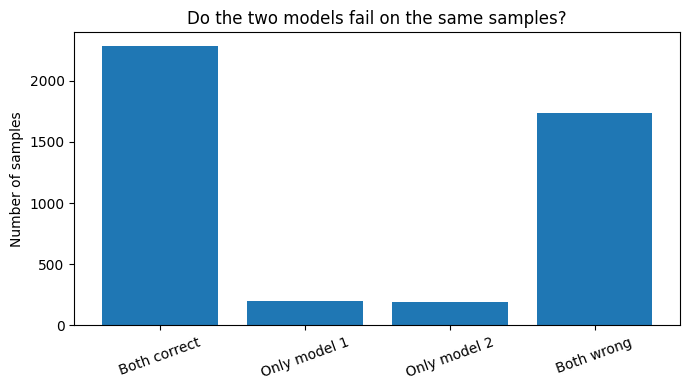


Summary:
Only model 1 correct : 197
Only model 2 correct : 192
Both wrong           : 1737


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier


# =============================
# Minimal configuration
# =============================
K_FEATURES = 400
REG_BASELINE = dict(min_child_weight=1, gamma=0.0, reg_lambda=1.0, reg_alpha=0.0)

MODELS = [
    dict(name="xgb_7_010", n_estimators=500, max_depth=7, learning_rate=0.10, imputer=KNNImputer(n_neighbors=1)),
    dict(name="xgb_9_003", n_estimators=500, max_depth=9, learning_rate=0.03, imputer=KNNImputer(n_neighbors=2)),
]



# =============================
# Session-wise z-score normalization (identical to the pipeline)
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = session_ids == sid
        mu = np.nanmean(Xn[idx], axis=0)
        std = np.nanstd(Xn[idx], axis=0)
        std[std < 1e-8] = 1.0
        Xn[idx] = (Xn[idx] - mu) / std
    return Xn


# =============================
# Load data
# =============================
df = pd.read_csv("data/raw/train.csv")
ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

df = df.drop(columns=[c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1])
feature_cols = [c for c in df.columns if c not in ID_COLS]

X = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

le = LabelEncoder()
y = le.fit_transform(y_str)

X = zscore_per_session(X, groups)

logo = LeaveOneGroupOut()


# =============================
# Out-of-fold predictions for each model
# =============================
oof_preds = {}

for cfg in MODELS:
    y_pred = np.full_like(y, -1)

    for train_idx, test_idx in logo.split(X, y, groups):
        X_tr, X_te = X[train_idx], X[test_idx]
        y_tr = y[train_idx]

        # Imputation
        imp = cfg["imputer"]
        X_tr = imp.fit_transform(X_tr)
        X_te = imp.transform(X_te)

        # Feature selection
        scores, _ = f_classif(X_tr, y_tr)
        scores = np.nan_to_num(scores, nan=-np.inf)
        feat_idx = np.argsort(scores)[-K_FEATURES:]

        # Model
        model = XGBClassifier(
            n_estimators=cfg["n_estimators"],
            max_depth=cfg["max_depth"],
            learning_rate=cfg["learning_rate"],
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=len(le.classes_),
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
            **REG_BASELINE,
        )

        model.fit(X_tr[:, feat_idx], y_tr)
        y_pred[test_idx] = model.predict(X_te[:, feat_idx])

    oof_preds[cfg["name"]] = y_pred
    print(cfg["name"], "OOF acc =", accuracy_score(y, y_pred))


# =============================
# Error comparison (CORE ANALYSIS)
# =============================
p1 = oof_preds[MODELS[0]["name"]]
p2 = oof_preds[MODELS[1]["name"]]

c1 = (p1 == y)
c2 = (p2 == y)

both_correct = np.sum(c1 & c2)
only_1 = np.sum(c1 & ~c2)
only_2 = np.sum(~c1 & c2)
both_wrong = np.sum(~c1 & ~c2)

# =============================
# Very simple plot
# =============================
labels = ["Both correct", "Only model 1", "Only model 2", "Both wrong"]
values = [both_correct, only_1, only_2, both_wrong]

plt.figure(figsize=(7, 4))
plt.bar(labels, values)
plt.title("Do the two models fail on the same samples?")
plt.ylabel("Number of samples")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# =============================
# Clear summary message
# =============================
print("\nSummary:")
print(f"Only model 1 correct : {only_1}")
print(f"Only model 2 correct : {only_2}")
print(f"Both wrong           : {both_wrong}")


Since the two final models achieve comparable accuracy and exhibit a non-negligible fraction of complementary errors, we evaluate an ensemble of both models using equal weighting under a LOSO cross-validation scheme.

In [23]:
import numpy as np
import pandas as pd
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier


# =============================
# Fixed configuration (same pipeline as before)
# =============================
K_FEATURES = 400
REG_BASELINE = dict(min_child_weight=1, gamma=0.0, reg_lambda=1.0, reg_alpha=0.0)

MODELS = [
    dict(
        name="xgb_7_010",
        n_estimators=500,
        max_depth=7,
        learning_rate=0.10,
        imputer=KNNImputer(n_neighbors=1),
    ),
    dict(
        name="xgb_9_003",
        n_estimators=500,
        max_depth=9,
        learning_rate=0.03,
        imputer=KNNImputer(n_neighbors=2),
    ),
]


# =============================
# Session-wise z-score normalization (IDENTICAL)
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = session_ids == sid
        mu = np.nanmean(Xn[idx], axis=0)
        std = np.nanstd(Xn[idx], axis=0)
        std[std < 1e-8] = 1.0
        Xn[idx] = (Xn[idx] - mu) / std
    return Xn


# =============================
# Load training data
# =============================
df = pd.read_csv("data/raw/train.csv")
ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# Remove constant feature columns
df = df.drop(columns=[c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1])

feature_cols = [c for c in df.columns if c not in ID_COLS]

X = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

# Encode labels
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

# Normalize per session
X = zscore_per_session(X, groups)

logo = LeaveOneGroupOut()


# =============================
# LOSO ensemble evaluation (50 / 50)
# =============================
y_pred_oof = np.full_like(y, -1)

for fold_i, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
    X_tr_raw, X_te_raw = X[train_idx], X[test_idx]
    y_tr = y[train_idx]

    probas = []

    for cfg in MODELS:
        # 1) Imputation (fit on train only)
        imp = cfg["imputer"]
        X_tr = imp.fit_transform(X_tr_raw)
        X_te = imp.transform(X_te_raw)

        # 2) Feature selection (ANOVA, fit on train only)
        scores, _ = f_classif(X_tr, y_tr)
        scores = np.nan_to_num(scores, nan=-np.inf)
        feat_idx = np.argsort(scores)[-K_FEATURES:]

        X_tr_sel = X_tr[:, feat_idx]
        X_te_sel = X_te[:, feat_idx]

        # 3) Train XGBoost model
        model = XGBClassifier(
            n_estimators=cfg["n_estimators"],
            max_depth=cfg["max_depth"],
            learning_rate=cfg["learning_rate"],
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
            **REG_BASELINE,
        )

        model.fit(X_tr_sel, y_tr)
        probas.append(model.predict_proba(X_te_sel))

    # 4) 50 / 50 ensemble (probability averaging)
    proba_ensemble = 0.5 * probas[0] + 0.5 * probas[1]
    y_pred_oof[test_idx] = np.argmax(proba_ensemble, axis=1)

    print(f"Fold {fold_i:02d} completed")


# =============================
# Final LOSO ensemble accuracy
# =============================
acc = accuracy_score(y, y_pred_oof)
print(f"\nLOSO Ensemble (0.5 / 0.5) accuracy = {acc:.4f}")


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/2211810525.py:42: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xn[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Fold 01 completed
Fold 02 completed
Fold 03 completed
Fold 04 completed
Fold 05 completed
Fold 06 completed
Fold 07 completed
Fold 08 completed

LOSO Ensemble (0.5 / 0.5) accuracy = 0.5655


Since the LOSO ensemble already achieves strong performance—surpassing that of the individual models—we further explore this direction by explicitly leveraging the strengths of each model. Specifically, when one model exhibits high prediction confidence (maximum class probability > 0.75), its prediction is selected; otherwise, predictions are combined using an equal-weight (50/50) ensemble. 

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier


# =============================
# Fixed configuration (same pipeline as before)
# =============================
K_FEATURES = 400
THRESH = 0.75  # confidence threshold (arbitrary choice, should be tuned)

REG_BASELINE = dict(min_child_weight=1, gamma=0.0, reg_lambda=1.0, reg_alpha=0.0)

MODELS = [
    dict(
        name="xgb_7_010",
        n_estimators=500,
        max_depth=7,
        learning_rate=0.10,
        imputer=KNNImputer(n_neighbors=1),
    ),
    dict(
        name="xgb_9_003",
        n_estimators=500,
        max_depth=9,
        learning_rate=0.03,
        imputer=KNNImputer(n_neighbors=2),
    ),
]


# =============================
# Session-wise z-score normalization 
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = session_ids == sid
        mu = np.nanmean(Xn[idx], axis=0)
        std = np.nanstd(Xn[idx], axis=0)
        std[std < 1e-8] = 1.0
        Xn[idx] = (Xn[idx] - mu) / std
    return Xn


# =============================
# Load training data
# =============================
df = pd.read_csv("data/raw/train.csv")
ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# Remove constant feature columns
df = df.drop(columns=[c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1])

feature_cols = [c for c in df.columns if c not in ID_COLS]

X = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

# Encode labels
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

# Normalize per session
X = zscore_per_session(X, groups)

logo = LeaveOneGroupOut()


# =============================
# LOSO confidence-gated ensemble
# =============================
y_pred_oof = np.full_like(y, -1)

for fold_i, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
    X_tr_raw, X_te_raw = X[train_idx], X[test_idx]
    y_tr = y[train_idx]

    probas = []

    for cfg in MODELS:
        # 1) Imputation (fit on train only)
        imp = cfg["imputer"]
        X_tr = imp.fit_transform(X_tr_raw)
        X_te = imp.transform(X_te_raw)

        # 2) Feature selection (ANOVA, fit on train only)
        scores, _ = f_classif(X_tr, y_tr)
        scores = np.nan_to_num(scores, nan=-np.inf)
        feat_idx = np.argsort(scores)[-K_FEATURES:]

        X_tr_sel = X_tr[:, feat_idx]
        X_te_sel = X_te[:, feat_idx]

        # 3) Train XGBoost model
        model = XGBClassifier(
            n_estimators=cfg["n_estimators"],
            max_depth=cfg["max_depth"],
            learning_rate=cfg["learning_rate"],
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
            **REG_BASELINE,
        )

        model.fit(X_tr_sel, y_tr)
        probas.append(model.predict_proba(X_te_sel))

    proba1, proba2 = probas[0], probas[1]
    conf1 = np.max(proba1, axis=1)
    conf2 = np.max(proba2, axis=1)

    # Rule:
    # - if model1 confident -> take model1
    # - else if model2 confident -> take model2
    # - else -> average 50/50
    use1 = conf1 >= THRESH
    use2 = (~use1) & (conf2 >= THRESH)

    proba_ens = 0.5 * proba1 + 0.5 * proba2
    proba_ens[use1] = proba1[use1]
    proba_ens[use2] = proba2[use2]

    y_pred_oof[test_idx] = np.argmax(proba_ens, axis=1)

    print(f"Fold {fold_i:02d} completed")


# =============================
# Final LOSO accuracy
# =============================
acc = accuracy_score(y, y_pred_oof)
print(f"\nLOSO Confidence-Gated Ensemble (THRESH={THRESH}) accuracy = {acc:.4f}")


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/2734701791.py:44: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xn[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Fold 01 completed
Fold 02 completed
Fold 03 completed
Fold 04 completed
Fold 05 completed
Fold 06 completed
Fold 07 completed
Fold 08 completed

LOSO Confidence-Gated Ensemble (THRESH=0.75) accuracy = 0.5655


Both ensemble models reach the same accuracy, we can arbitrarily choose the first model because it's simplier. 

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.impute import KNNImputer

from xgboost import XGBClassifier


# =============================
# Fixed configuration
# =============================
K_FEATURES = 400

REG_BASELINE = dict(
    min_child_weight=1,
    gamma=0.0,
    reg_lambda=1.0,
    reg_alpha=0.0,
)

MODELS = [
    dict(
        name="xgb_7_010",
        n_estimators=500,
        max_depth=7,
        learning_rate=0.10,
        imputer=KNNImputer(n_neighbors=1),
    ),
    dict(
        name="xgb_9_003",
        n_estimators=500,
        max_depth=9,
        learning_rate=0.03,
        imputer=KNNImputer(n_neighbors=2),
    ),
]


# =============================
# Session-wise z-score normalization 
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = session_ids == sid
        mu = np.nanmean(Xn[idx], axis=0)
        std = np.nanstd(Xn[idx], axis=0)
        std[std < 1e-8] = 1.0
        Xn[idx] = (Xn[idx] - mu) / std
    return Xn


# =============================
# 1) Load FULL training data
# =============================
train = pd.read_csv("data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# Remove constant feature columns
train = train.drop(
    columns=[c for c in train.columns if c not in ID_COLS and train[c].nunique() <= 1]
)

feature_cols = [c for c in train.columns if c not in ID_COLS]

X_train_raw = train[feature_cols].to_numpy()
y_train_str = train["TRIAL_TYPE"].to_numpy()
groups_train = train["session_id"].to_numpy()

# Encode labels
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)
num_classes = len(le.classes_)

print("Classes:", le.classes_)

# Normalize per session (train)
X_train_norm = zscore_per_session(X_train_raw, groups_train)


# =============================
# 2) Load TEST data
# =============================
test = pd.read_csv("data/raw/test.csv")

needed_cols = ["session_id", "trial_number"] + feature_cols
test = test[needed_cols].copy()

X_test_raw = test[feature_cols].to_numpy()
groups_test = test["session_id"].to_numpy()

# Normalize per session (test)
X_test_norm = zscore_per_session(X_test_raw, groups_test)


# =============================
# 3) Train both models + predict probabilities
# =============================
test_probas = []

for cfg in MODELS:
    print(f"Training model: {cfg['name']}")

    # --- Imputation (fit on FULL train) ---
    imputer = cfg["imputer"]
    X_tr_imp = imputer.fit_transform(X_train_norm)
    X_te_imp = imputer.transform(X_test_norm)

    # --- Feature selection (ANOVA, fit on FULL train) ---
    scores, _ = f_classif(X_tr_imp, y_train)
    scores = np.nan_to_num(scores, nan=-np.inf)

    feat_idx = np.argsort(scores)[-K_FEATURES:]

    X_tr_final = X_tr_imp[:, feat_idx]
    X_te_final = X_te_imp[:, feat_idx]

    # --- Train XGBoost ---
    model = XGBClassifier(
        n_estimators=cfg["n_estimators"],
        max_depth=cfg["max_depth"],
        learning_rate=cfg["learning_rate"],
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=0,
        n_jobs=-1,
        **REG_BASELINE,
    )

    model.fit(X_tr_final, y_train)

    # --- Predict probabilities on test ---
    test_probas.append(model.predict_proba(X_te_final))


# =============================
# 4) 50 / 50 ensemble (probability averaging)
# =============================
proba_ensemble = 0.5 * test_probas[0] + 0.5 * test_probas[1]
y_pred_int = np.argmax(proba_ensemble, axis=1)
y_pred_str = le.inverse_transform(y_pred_int)


# =============================
# 5) Build Kaggle submission file
# =============================
sample = pd.read_csv("data/raw/sample_submission.csv")

submission = sample.copy()
submission["TRIAL_TYPE"] = y_pred_str

out_path = "submission__FULLTRAIN__ENSEMBLE50_50__zscoreSession__KNN1_KNN2__FscoreK400__XGBbaseline.csv"
submission.to_csv(out_path, index=False)

print(f"\nSubmission saved to: {out_path}")
print(submission.head())


Classes: ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3373692190.py:47: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xn[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3373692190.py:47: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xn[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Training model: xgb_7_010
Training model: xgb_9_003

Submission saved to: submission__FULLTRAIN__ENSEMBLE50_50__zscoreSession__KNN1_KNN2__FscoreK400__XGBbaseline.csv
   ID      TRIAL_TYPE
0   1  NOGO W- nolick
1   2      GO W+ lick
2   3    GO W- nolick
3   4      GO W+ lick
4   5      GO W+ lick


After Kaggle submission when applied to the test set, the resulting accuracy was slightly lower than the individual xgb_7_010 model. The ensemble underperforms the best single model on the test set, likely due to partial error overlap and the dilution of a slightly dominant model when averaging predictions.